# So sánh các mô hình dự báo doanh thu

Notebook này trực quan hóa kết quả đã được tổng hợp trong `outputs/evaluation/`; không huấn luyện lại mô hình và không tính lại các metrics. Có thể chạy từ thư mục gốc dự án hoặc từ thư mục `notebooks`.

Các mô hình: **Baseline**, **SARIMA**, **XGBoost**, **Hybrid**. Các chuỗi: **total**, **online**, **store**, **mobile**. Mỗi kỳ gồm các tuần đánh giá Val2023, Val2024 hoặc Test2025.

| Metric | Ý nghĩa | Tốt hơn |
|---|---|---|
| MAE | Sai số tuyệt đối trung bình, cùng đơn vị doanh thu | Thấp |
| RMSE | Phạt mạnh hơn các sai số lớn, cùng đơn vị doanh thu | Thấp |
| sMAPE | Sai số phần trăm đối xứng | Thấp |
| WAPE | Tổng sai số tuyệt đối chia tổng doanh thu thực tế | Thấp |

**Cách đọc:** thứ hạng và số lần thắng trong notebook dựa trên RMSE, nhất quán với artifact xếp hạng. Test2025 là kết quả báo cáo cuối cùng, không dùng để chọn hay tinh chỉnh mô hình. So sánh ở đây mang tính mô tả, không phải kiểm định ý nghĩa thống kê.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titleweight"] = "bold"

# Locate the project root by searching the current directory and its parents.
search_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in search_roots if (p / "outputs" / "evaluation").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find outputs/evaluation. Run this notebook from the project "
        "root or one of its subdirectories."
    )

EVALUATION_DIR = PROJECT_ROOT / "outputs" / "evaluation"
print(f"Project root: {PROJECT_ROOT}")
print(f"Evaluation directory: {EVALUATION_DIR}")

Project root: d:\project_git\retail-revenue-forecasting
Evaluation directory: d:\project_git\retail-revenue-forecasting\outputs\evaluation


In [2]:
comparison_path = EVALUATION_DIR / "comparison.csv"
forecasts_path = EVALUATION_DIR / "normalized_forecasts.csv"
missing = [p.name for p in (comparison_path, forecasts_path) if not p.exists()]
if missing:
    raise FileNotFoundError(
        f"Missing artifacts: {', '.join(missing)}. Run "
        "`python src/evaluation_pipeline.py` followed by "
        "`python src/model_comparison.py` from the project root."
    )

metrics = pd.read_csv(comparison_path)
forecasts = pd.read_csv(forecasts_path, parse_dates=["week_start"])
metric_columns = ["MAE", "RMSE", "sMAPE", "WAPE"]
required_metrics = {"series", "period", "model", *metric_columns}
required_forecasts = {"series", "period", "week_start", "actual", "forecast", "model_name"}
if not required_metrics.issubset(metrics.columns):
    raise ValueError(f"comparison.csv is missing columns: {sorted(required_metrics - set(metrics.columns))}")
if not required_forecasts.issubset(forecasts.columns):
    raise ValueError(
        f"normalized_forecasts.csv is missing columns: "
        f"{sorted(required_forecasts - set(forecasts.columns))}"
    )

period_order = [p for p in ["val2023", "val2024", "test2025"] if p in metrics["period"].unique()]
series_order = [s for s in ["total", "online", "store", "mobile"] if s in metrics["series"].unique()]
model_order = [m for m in ["Baseline", "SARIMA", "XGBoost", "Hybrid"] if m in metrics["model"].unique()]
period_labels = {"val2023": "Val2023", "val2024": "Val2024", "test2025": "Test2025"}
series_labels = {"total": "Total", "online": "Online", "store": "Store", "mobile": "Mobile"}
metric_labels = {"MAE": "MAE", "RMSE": "RMSE", "sMAPE": "sMAPE (%)", "WAPE": "WAPE (%)"}

print(f"{len(metrics):,} metric rows | {len(forecasts):,} forecast observations")
print(f"Periods: {', '.join(period_labels.get(p, p) for p in period_order)}")
print(f"Models: {', '.join(model_order)}")
display(metrics.head())

48 metric rows | 2,512 forecast observations
Periods: Val2023, Val2024, Test2025
Models: Baseline, SARIMA, XGBoost, Hybrid


,series,period,model,MAE,RMSE,sMAPE,WAPE,n_rows
0,total,val2023,Baseline,529.1442,664.8961,15.7710,15.3807,52
1,online,val2023,Baseline,348.6530,458.2901,32.6070,31.4928,52
2,store,val2023,Baseline,344.7170,434.6138,28.8822,27.5983,52
3,mobile,val2023,Baseline,303.5346,365.1286,30.3572,27.9968,52
4,total,val2024,Baseline,545.5973,650.5405,16.1527,16.2468,53


## Dashboard so sánh

In [3]:
def render_dashboard(selected_series="All", selected_period=None, selected_metric="RMSE"):
    """Plot model comparisons for the selected series and evaluation period."""
    period = selected_period or period_order[-1]
    series_filter = series_order if selected_series == "All" else [selected_series]
    period_data = metrics[
        metrics["period"].eq(period) & metrics["series"].isin(series_filter)
    ].copy()
    period_forecasts = forecasts[
        forecasts["period"].eq(period) & forecasts["series"].isin(series_filter)
    ].copy()
    if period_data.empty or period_forecasts.empty:
        raise ValueError(f"No data available for series={selected_series}, period={period}.")

    # 1. RMSE by model and series.
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    heat = period_data.pivot(index="model", columns="series", values="RMSE")
    heat = heat.reindex(index=model_order, columns=series_filter)
    sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu_r", linewidths=.5, ax=axes[0, 0])
    axes[0, 0].set_title(f"RMSE by model - {period_labels.get(period, period)}")
    axes[0, 0].set_xlabel("Revenue series")
    axes[0, 0].set_ylabel("Model")
    axes[0, 0].set_xticklabels([series_labels.get(x.get_text(), x.get_text()) for x in axes[0, 0].get_xticklabels()])

    # 2. Compare models using the selected metric.
    sns.barplot(
        data=period_data, x="series", y=selected_metric, hue="model",
        hue_order=model_order, order=series_filter, ax=axes[0, 1],
    )
    axes[0, 1].set_title(f"{metric_labels[selected_metric]} by series - {period_labels.get(period, period)}")
    axes[0, 1].set_xlabel("Revenue series")
    axes[0, 1].set_ylabel(metric_labels[selected_metric])
    axes[0, 1].set_xticklabels([series_labels.get(x.get_text(), x.get_text()) for x in axes[0, 1].get_xticklabels()])
    axes[0, 1].legend(title="Model", fontsize=8)

    # 3. Count series-period pairs where each model has the lowest RMSE.
    winners = metrics.loc[metrics.groupby(["series", "period"])["RMSE"].idxmin()].copy()
    winners = winners[winners["series"].isin(series_filter)]
    wins = winners.groupby("model").size().reindex(model_order, fill_value=0)
    sns.barplot(x=wins.index, y=wins.values, color=sns.color_palette()[0], ax=axes[1, 0])
    axes[1, 0].set_title("Number of RMSE wins - all periods")
    axes[1, 0].set_xlabel("Model")
    axes[1, 0].set_ylabel("Winning series-period pairs")
    axes[1, 0].tick_params(axis="x", rotation=15)
    for container in axes[1, 0].containers:
        axes[1, 0].bar_label(container, fmt="%d")

    # 4. Compare weekly actuals and forecasts for each model.
    focus_series = selected_series if selected_series != "All" else "total"
    line_data = period_forecasts[period_forecasts["series"].eq(focus_series)].copy()
    if line_data.empty:
        focus_series = series_filter[0]
        line_data = period_forecasts[period_forecasts["series"].eq(focus_series)].copy()
    ax = axes[1, 1]
    actual = line_data[["week_start", "actual"]].drop_duplicates().sort_values("week_start")
    ax.plot(actual["week_start"], actual["actual"], color="black", linewidth=2.4, label="Actual")
    for model in model_order:
        model_data = line_data[line_data["model_name"].eq(model)].sort_values("week_start")
        if not model_data.empty:
            ax.plot(model_data["week_start"], model_data["forecast"], linewidth=1.3, alpha=.85, label=model)
    ax.set_title(f"Weekly actuals and forecasts - {series_labels.get(focus_series, focus_series)}")
    ax.set_xlabel("Week starting")
    ax.set_ylabel("Revenue")
    ax.legend(title="", fontsize=8, ncol=2)
    fig.suptitle("Model comparison overview", fontsize=16, fontweight="bold")
    plt.show()

    # 5. Residual distributions; positive residuals indicate under-forecasting.
    residual_data = period_forecasts.copy()
    if "residual" not in residual_data.columns:
        residual_data["residual"] = residual_data["actual"] - residual_data["forecast"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
    sns.boxplot(data=residual_data, x="model_name", y="residual", order=model_order, ax=axes[0])
    axes[0].axhline(0, color="black", linewidth=1, linestyle="--")
    axes[0].set_title("Residual distribution by model")
    axes[0].set_xlabel("Model")
    axes[0].set_ylabel("Residual = actual - forecast")
    sns.histplot(
        data=residual_data, x="residual", hue="model_name", hue_order=model_order,
        element="step", stat="density", common_norm=False, fill=False, ax=axes[1],
    )
    axes[1].axvline(0, color="black", linewidth=1, linestyle="--")
    axes[1].set_title("Residual distribution")
    axes[1].set_xlabel("Residual = actual - forecast")
    axes[1].set_ylabel("Density")
    plt.show()

    # RMSE ranking table for the selected series and period.
    ranking = period_data.sort_values(["series", "RMSE"]).copy()
    ranking["Rank"] = ranking.groupby("series")["RMSE"].rank(method="min").astype(int)
    ranking["Series"] = ranking["series"].map(series_labels)
    display(
        ranking[["Series", "model", "Rank", "MAE", "RMSE", "sMAPE", "WAPE"]]
        .rename(columns={"model": "Model", "sMAPE": "sMAPE (%)", "WAPE": "WAPE (%)"})
        .sort_values(["Series", "Rank"])
        .round(2)
        .reset_index(drop=True)
    )


try:
    import ipywidgets as widgets
except ImportError:
    print("ipywidgets is not installed; displaying the default dashboard (Test2025, all series).")
    render_dashboard()
else:
    display(widgets.interactive(
        render_dashboard,
        selected_series=widgets.Dropdown(
            options=[("All", "All")] + [(series_labels[s], s) for s in series_order],
            value="All", description="Series:",
        ),
        selected_period=widgets.Dropdown(
            options=[(period_labels.get(p, p), p) for p in period_order],
            value="test2025" if "test2025" in period_order else period_order[-1], description="Period:",
        ),
        selected_metric=widgets.Dropdown(
            options=[(metric_labels[m], m) for m in metric_columns],
            value="RMSE", description="Metric:",
        ),
    ))

interactive(children=(Dropdown(description='Series:', options=(('All', 'All'), ('Total', 'total'), ('Online', …

## Tóm tắt kết quả

Bảng dưới đây tính số lần RMSE thấp nhất trên tất cả cặp chuỗi-kỳ và metric trung bình theo mô hình. Trung bình chỉ dùng để mô tả; do quy mô doanh thu giữa các chuỗi khác nhau, nên ưu tiên so sánh trong cùng một chuỗi và kỳ. Không kết luận model tốt nhất chỉ từ một metric hoặc một kỳ.

In [4]:
best_rows = metrics.loc[metrics.groupby(["series", "period"])["RMSE"].idxmin()].copy()
best_rows["Series"] = best_rows["series"].map(series_labels)
best_rows["Period"] = best_rows["period"].map(period_labels)
print("Model with the lowest RMSE for each series and period:")
display(
    best_rows[["Series", "Period", "model", "RMSE", "MAE", "WAPE"]]
    .rename(columns={"model": "Model", "WAPE": "WAPE (%)"})
    .sort_values(["Period", "Series"])
    .round(2)
    .reset_index(drop=True)
)

wins = best_rows["model"].value_counts().reindex(model_order, fill_value=0)
average = metrics.groupby("model")[metric_columns].mean().reindex(model_order).round(2)
summary = average.copy()
summary.insert(0, "RMSE wins", wins)
display(summary.rename(columns={"sMAPE": "sMAPE (%)", "WAPE": "WAPE (%)"}))
best_model = wins.idxmax()
print(
    f"Based on the available results, {best_model} achieved the lowest RMSE in "
    f"{int(wins.max())} of {len(best_rows)} series-period pairs. This is descriptive evidence; "
    "consider the metric, series, and period before making a decision."
)

Model with the lowest RMSE for each series and period:


,Series,Period,Model,RMSE,MAE,WAPE (%)
0,Mobile,Test2025,XGBoost,429.91,344.12,29.33
1,Online,Test2025,SARIMA,418.99,330.61,29.17
2,Store,Test2025,Baseline,440.74,342.86,31.55
3,Total,Test2025,XGBoost,747.32,573.82,16.91
4,Mobile,Val2023,Baseline,365.13,303.53,28.00
5,Online,Val2023,XGBoost,452.92,342.96,30.98
6,Store,Val2023,Baseline,434.61,344.72,27.60
7,Total,Val2023,XGBoost,653.27,547.56,15.92
8,Mobile,Val2024,Hybrid,350.31,269.98,23.72
9,Online,Val2024,SARIMA,365.64,298.34,27.39


,RMSE wins,MAE,RMSE,sMAPE (%),WAPE (%)
model,,,,,
Baseline,3,384.10,480.16,26.56,25.77
SARIMA,3,377.63,477.04,26.26,25.44
XGBoost,5,379.91,475.92,26.19,25.42
Hybrid,1,385.73,484.43,26.65,25.85


Based on the available results, XGBoost achieved the lowest RMSE in 5 of 12 series-period pairs. This is descriptive evidence; consider the metric, series, and period before making a decision.


## Phân tích theo thời gian và kênh

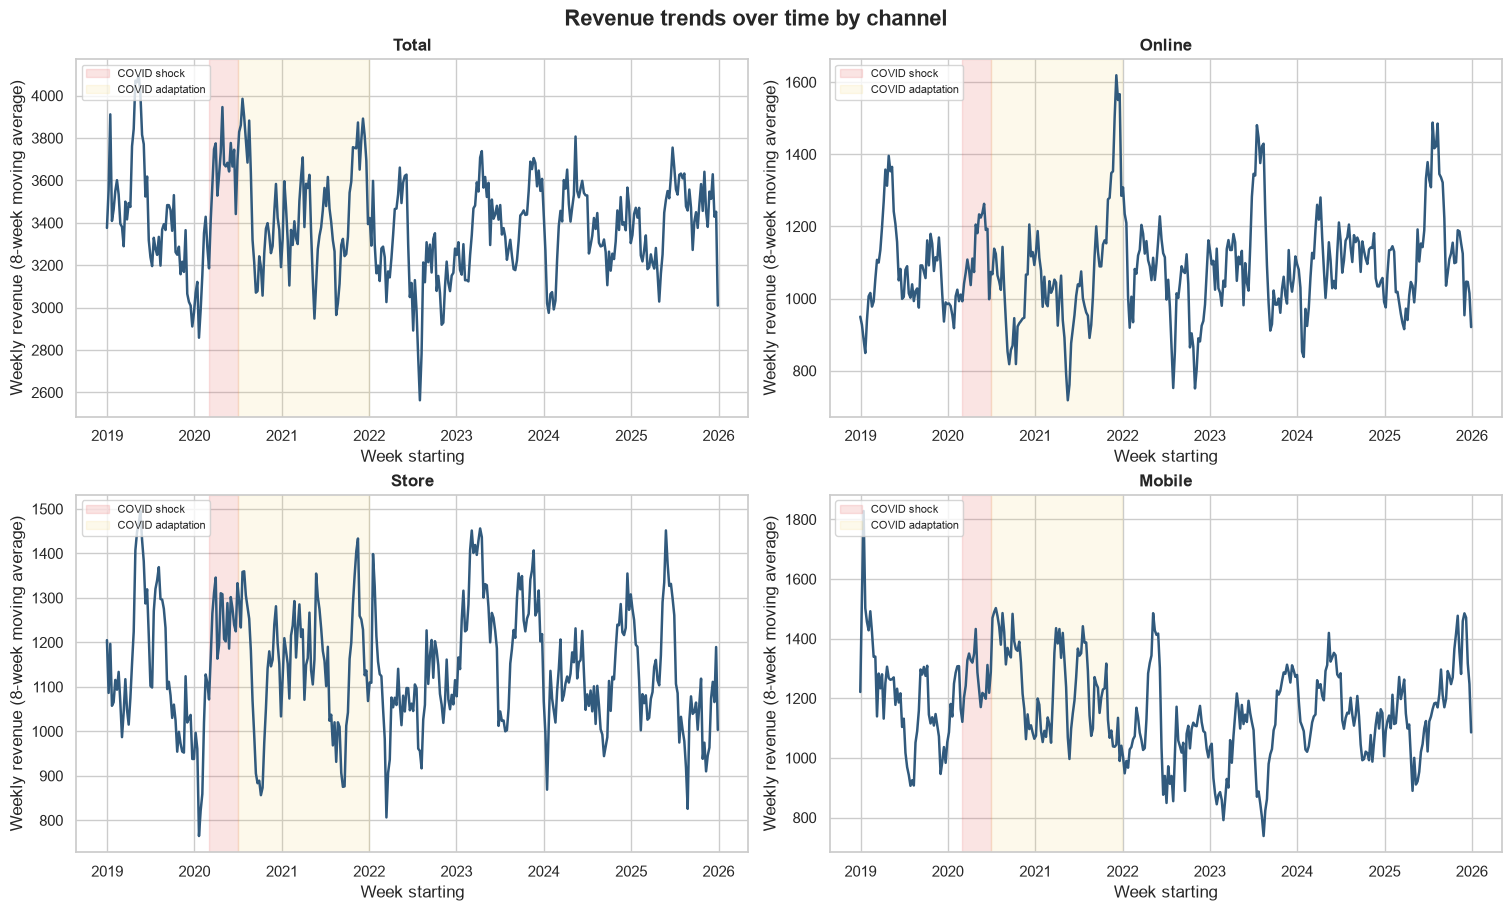

,Series,COVID phase,Weeks,Mean weekly revenue,Change vs. pre-COVID (%)
0,Mobile,COVID adaptation,78,1224.1,3.1
1,Mobile,COVID shock,19,1284.1,8.2
2,Mobile,Post-COVID,209,1119.5,-5.7
3,Mobile,Pre-COVID,60,1187.0,0.0
4,Online,COVID adaptation,78,1061.5,-1.5
5,Online,COVID shock,19,1134.7,5.3
6,Online,Post-COVID,209,1092.7,1.4
7,Online,Pre-COVID,60,1077.3,0.0
8,Store,COVID adaptation,78,1139.5,0.4
9,Store,COVID shock,19,1239.0,9.2


COVID phases represented in model evaluation weeks: Post-COVID
Error metrics by phase only cover phases present in the evaluation data; there are no model evaluation results for COVID shock/adaptation.


In [5]:
total_path = PROJECT_ROOT / "data" / "processed" / "weekly_total.csv"
channel_path = PROJECT_ROOT / "data" / "processed" / "weekly_channel.csv"
if not total_path.exists() or not channel_path.exists():
    raise FileNotFoundError("Weekly data is missing: expected data/processed/weekly_total.csv and weekly_channel.csv. Run src/preprocess.py.")

weekly_total = pd.read_csv(total_path, parse_dates=["week_start"])
weekly_channel = pd.read_csv(channel_path, parse_dates=["week_start"])
weekly_total["series"] = "total"
weekly_channel["series"] = weekly_channel["channel"].str.lower()
weekly = pd.concat([
    weekly_total[["week_start", "revenue", "series", "covid_phase"]],
    weekly_channel[["week_start", "revenue", "series", "covid_phase"]],
], ignore_index=True)
weekly["week_start"] = pd.to_datetime(weekly["week_start"])
phase_order = ["pre_covid", "covid_shock", "covid_adaptation", "post_covid"]
phase_labels = {
    "pre_covid": "Pre-COVID", "covid_shock": "COVID shock",
    "covid_adaptation": "COVID adaptation", "post_covid": "Post-COVID",
}
phase_colors = {
    "pre_covid": "#4C78A8", "covid_shock": "#E45756",
    "covid_adaptation": "#F2CF5B", "post_covid": "#72B7B2",
}

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for ax, series in zip(axes.flat, ["total", "online", "store", "mobile"]):
    part = weekly[weekly["series"].eq(series)].sort_values("week_start").copy()
    part["revenue_smooth"] = part["revenue"].rolling(8, min_periods=1).mean()
    ax.plot(part["week_start"], part["revenue_smooth"], color="#315A7D", linewidth=1.8)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-30"), color="#E45756", alpha=.16, label="COVID shock")
    ax.axvspan(pd.Timestamp("2020-07-01"), pd.Timestamp("2021-12-31"), color="#F2CF5B", alpha=.12, label="COVID adaptation")
    ax.set_title(series_labels.get(series, series))
    ax.set_xlabel("Week starting")
    ax.set_ylabel("Weekly revenue (8-week moving average)")
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Revenue trends over time by channel", fontsize=16, fontweight="bold")
plt.show()

phase_summary = (
    weekly.groupby(["series", "covid_phase"], as_index=False)
    .agg(mean_weekly_revenue=("revenue", "mean"), total_revenue=("revenue", "sum"), weeks=("revenue", "size"))
)
pre_covid_avg = phase_summary[phase_summary["covid_phase"].eq("pre_covid")].set_index("series")["mean_weekly_revenue"]
phase_summary["change_vs_pre_covid_pct"] = phase_summary.apply(
    lambda row: (row["mean_weekly_revenue"] / pre_covid_avg[row["series"]] - 1) * 100
    if row["series"] in pre_covid_avg.index and pre_covid_avg[row["series"]] != 0 else float("nan"),
    axis=1,
)
phase_summary["Series"] = phase_summary["series"].map(series_labels)
phase_summary["COVID phase"] = phase_summary["covid_phase"].map(phase_labels)
display(
    phase_summary[["Series", "COVID phase", "weeks", "mean_weekly_revenue", "change_vs_pre_covid_pct"]]
    .rename(columns={"weeks": "Weeks", "mean_weekly_revenue": "Mean weekly revenue", "change_vs_pre_covid_pct": "Change vs. pre-COVID (%)"})
    .sort_values(["Series", "COVID phase"])
    .round(1)
    .reset_index(drop=True)
)

phase_metric_path = EVALUATION_DIR / "covid_phase_comparison.csv"
if phase_metric_path.exists():
    covid_metrics = pd.read_csv(phase_metric_path)
    evaluated_phases = sorted(covid_metrics["covid_phase"].dropna().unique())
    print("COVID phases represented in model evaluation weeks:", ", ".join(phase_labels.get(p, p) for p in evaluated_phases))
    print("Error metrics by phase only cover phases present in the evaluation data; there are no model evaluation results for COVID shock/adaptation.")
else:
    print("covid_phase_comparison.csv was not found; historical revenue by phase is shown, but model error breakdowns by phase are unavailable.")

## Business Insights


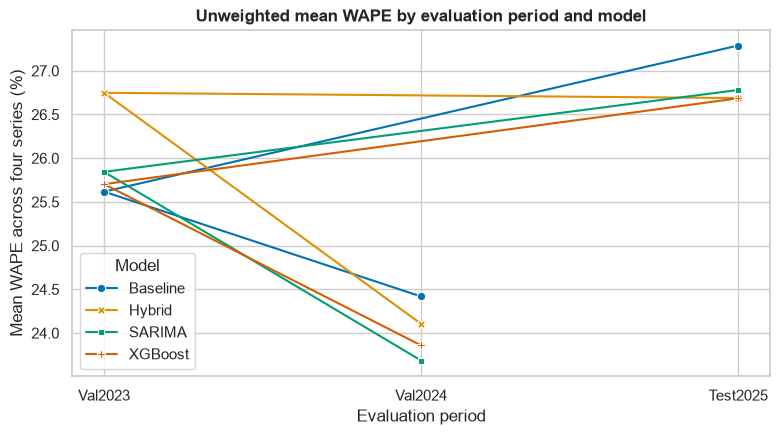

1) Model candidates by channel - selected on validation using mean WAPE:


,Series,Validation candidate,Mean WAPE (%),Mean RMSE
0,Mobile,XGBoost,25.85,369.22
1,Online,SARIMA,29.09,410.71
2,Store,XGBoost,28.09,406.05
3,Total,SARIMA,15.34,645.20


2) Lowest-RMSE model on Test2025 - final reporting only; not used for retuning:


,Series,Test2025 leader,RMSE,WAPE (%)
0,Mobile,XGBoost,429.91,29.33
1,Online,SARIMA,418.99,29.17
2,Store,Baseline,440.74,31.55
3,Total,XGBoost,747.32,16.91


3) Unweighted mean percentage error across evaluation periods:


,Period,Mean WAPE across four series (%)
0,Test2025,26.86
1,Val2023,25.98
2,Val2024,24.02


In [6]:
validation = metrics[metrics["period"].isin(["val2023", "val2024"])].copy()
validation_by_channel = validation.groupby(["series", "model"], as_index=False).agg(
    mean_WAPE=("WAPE", "mean"), mean_RMSE=("RMSE", "mean"), validation_splits=("period", "nunique")
)
validation_winners = validation_by_channel.loc[
    validation_by_channel.groupby("series")["mean_WAPE"].idxmin()
].sort_values("series")
test_rows = metrics[metrics["period"].eq("test2025")].copy()
test_winners = test_rows.loc[test_rows.groupby("series")["RMSE"].idxmin()].sort_values("series")
wape_by_period = metrics.groupby("period", as_index=False)["WAPE"].mean()
period_wape = metrics.groupby(["period", "model"], as_index=False).agg(mean_WAPE=("WAPE", "mean"))
period_wape["period"] = pd.Categorical(period_wape["period"], categories=period_order, ordered=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=period_wape, x="period", y="mean_WAPE", hue="model", style="model", markers=True, dashes=False, sort=False, ax=ax)
ax.set_xticks(range(len(period_order)), [period_labels.get(p, p) for p in period_order])
ax.set_title("Unweighted mean WAPE by evaluation period and model")
ax.set_xlabel("Evaluation period")
ax.set_ylabel("Mean WAPE across four series (%)")
ax.legend(title="Model")
plt.show()

print("1) Model candidates by channel - selected on validation using mean WAPE:")
recommendations = validation_winners[["series", "model", "mean_WAPE", "mean_RMSE"]].copy()
recommendations["Series"] = recommendations["series"].map(series_labels)
display(
        recommendations[["Series", "model", "mean_WAPE", "mean_RMSE"]]
        .rename(columns={"model": "Validation candidate", "mean_WAPE": "Mean WAPE (%)", "mean_RMSE": "Mean RMSE"})
    .round(2)
    .reset_index(drop=True)
)

print("2) Lowest-RMSE model on Test2025 - final reporting only; not used for retuning:")
test_winners["Series"] = test_winners["series"].map(series_labels)
display(
    test_winners[["Series", "model", "RMSE", "WAPE"]]
    .rename(columns={"model": "Test2025 leader", "WAPE": "WAPE (%)"})
    .round(2)
    .reset_index(drop=True)
)

print("3) Unweighted mean percentage error across evaluation periods:")
display(
    wape_by_period.assign(Period=wape_by_period["period"].map(period_labels))
    [["Period", "WAPE"]].rename(columns={"WAPE": "Mean WAPE across four series (%)"}).round(2)
)

channel_validation = validation[validation["series"].isin(["online", "store", "mobile"])]
channel_wape = channel_validation.groupby("series")["WAPE"].mean()
hardest_channel = channel_wape.idxmax()
lowest_channel = channel_wape.idxmin()
phase_changes = phase_summary.pivot(index="series", columns="covid_phase", values="change_vs_pre_covid_pct")
